# Partie III — Variational Autoencoder (VAE)

## 0. Préparation

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("Device :", device)

PyTorch : 2.14.1+cu126
Device : cuda


In [2]:
# Pixels dans [0, 1] : adaptés à la sortie Sigmoid du décodeur
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


## 8. Principe

Au lieu d'associer une entrée $x$ à un point latent unique, le VAE l'associe à une distribution
$q(z|x)=\mathcal{N}(\mu,\sigma^2)$. L'encodeur produit $\mu(x)$ et $\log \sigma^2(x)$, puis on échantillonne $z$.

## 9. Reparameterization trick

On veut échantillonner $z \sim \mathcal{N}(\mu,\sigma^2)$ tout en conservant la rétropropagation.
On tire $\epsilon \sim \mathcal{N}(0,I)$ puis on calcule $\boxed{z=\mu+\sigma\odot\epsilon}$ :
le hasard est isolé dans $\epsilon$, et les gradients peuvent traverser $\mu$ et $\sigma$.

In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

## 10. Loss et entraînement du VAE

La loss combine deux termes :
- **Reconstruction** $\mathcal{L}_{rec}$ : entropie croisée binaire entre les pixels d'origine et reconstruits ;
- **Régularisation** $D_{KL}(q(z|x) \parallel \mathcal N(0,I)) = -\frac12 \sum (1+\log\sigma^2-\mu^2-\sigma^2)$,
  qui pousse chaque distribution latente vers une loi normale standard.

$\boxed{\mathcal L_{VAE} = \mathcal L_{rec} + \beta D_{KL}}$

| Terme | Ce qu'il encourage |
|---|---|
| Reconstruction | garder l'information spécifique à chaque image |
| Divergence KL | rendre les distributions latentes compatibles avec une référence commune |

Le modèle cherche un compromis : des codes assez différents pour distinguer un « 3 » d'un « 8 », mais assez organisés
pour permettre de nouveaux tirages. Une régularisation trop forte ($\beta$ élevé) peut pousser le décodeur à
ignorer le code latent : c'est l'**effondrement du posterior** (*posterior collapse*).

In [4]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(x_hat, x, reduction="sum")

    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [5]:
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()
    history = []

    for epoch in range(epochs):
        total_loss = 0
        total_rec = 0
        total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)

            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=beta)

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)
        history.append((total_loss / n, total_rec / n, total_kl / n))

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss={total_loss/n:.2f} | "
            f"Rec={total_rec/n:.2f} | "
            f"KL={total_kl/n:.2f}"
        )

    return history

vae_history = train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=194.38 | Rec=190.26 | KL=4.12
Epoch 2/20 | Loss=167.31 | Rec=162.48 | KL=4.84
Epoch 3/20 | Loss=161.73 | Rec=156.53 | KL=5.20
Epoch 4/20 | Loss=157.78 | Rec=152.34 | KL=5.44
Epoch 5/20 | Loss=154.79 | Rec=149.18 | KL=5.61
Epoch 6/20 | Loss=152.59 | Rec=146.86 | KL=5.72
Epoch 7/20 | Loss=150.99 | Rec=145.18 | KL=5.81
Epoch 8/20 | Loss=149.74 | Rec=143.84 | KL=5.90
Epoch 9/20 | Loss=148.60 | Rec=142.63 | KL=5.96
Epoch 10/20 | Loss=147.89 | Rec=141.86 | KL=6.03
Epoch 11/20 | Loss=146.99 | Rec=140.92 | KL=6.08
Epoch 12/20 | Loss=146.35 | Rec=140.22 | KL=6.13
Epoch 13/20 | Loss=145.56 | Rec=139.37 | KL=6.19
Epoch 14/20 | Loss=145.11 | Rec=138.91 | KL=6.20
Epoch 15/20 | Loss=144.77 | Rec=138.53 | KL=6.24
Epoch 16/20 | Loss=144.21 | Rec=137.95 | KL=6.26
Epoch 17/20 | Loss=143.71 | Rec=137.41 | KL=6.29
Epoch 18/20 | Loss=143.31 | Rec=136.99 | KL=6.32
Epoch 19/20 | Loss=143.11 | Rec=136.76 | KL=6.35
Epoch 20/20 | Loss=142.59 | Rec=136.22 | KL=6.37


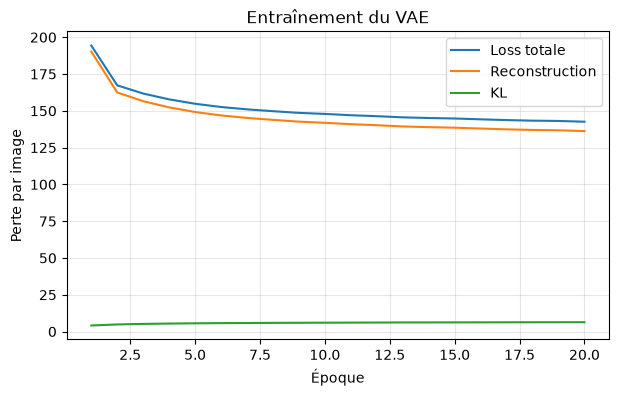

In [6]:
historique = np.array(vae_history)
epochs = range(1, len(historique) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, historique[:, 0], label="Loss totale")
plt.plot(epochs, historique[:, 1], label="Reconstruction")
plt.plot(epochs, historique[:, 2], label="KL")
plt.xlabel("Époque")
plt.ylabel("Perte par image")
plt.title("Entraînement du VAE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 11. Reconstruction avec le VAE

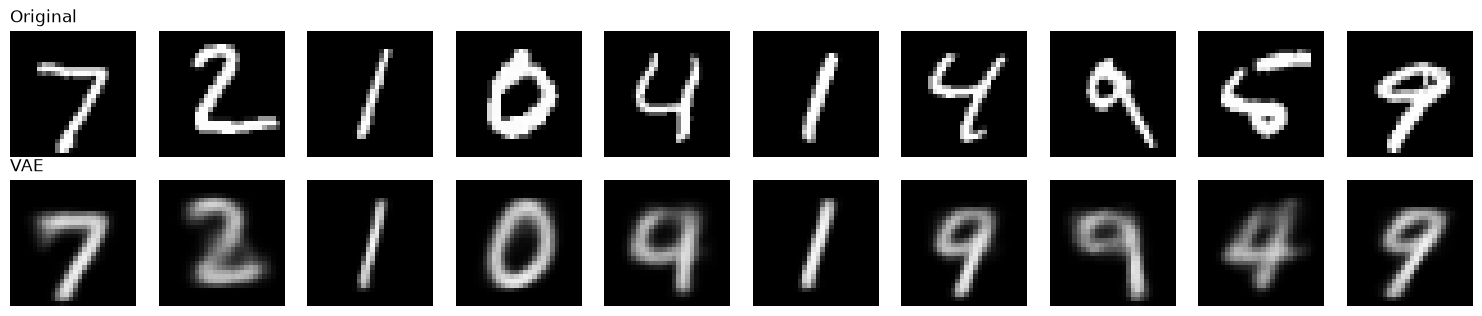

In [7]:
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3.2))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")

axes[0, 0].set_title("Original", loc="left")
axes[1, 0].set_title("VAE", loc="left")

plt.tight_layout()
plt.show()

## 12. Visualisation de l'espace latent du VAE

On affiche le vecteur moyen $\mu$ (et non $z$, qui contient du hasard) comme représentation latente.

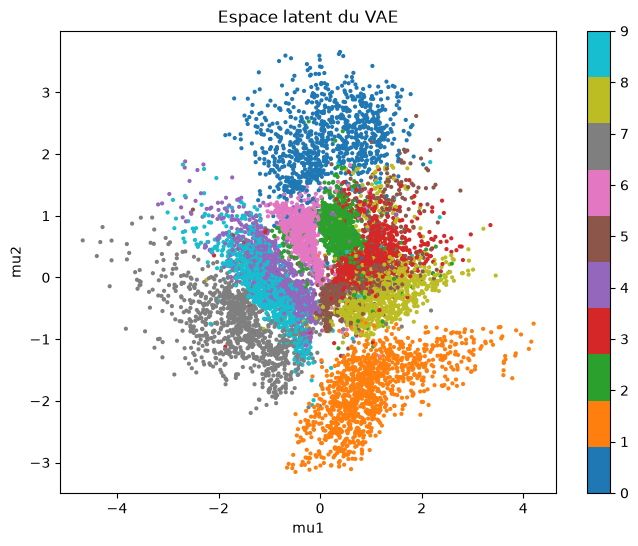

In [8]:
vae.eval()

mus = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(MU[:, 0], MU[:, 1], c=Y, cmap="tab10", s=4)
plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter, ticks=range(10))
plt.show()

Contrairement à l'autoencodeur, l'espace latent est centré sur 0, compact et sans grands trous :
c'est l'effet du terme KL, qui rapproche chaque distribution de $\mathcal N(0, I)$.

## 13. Générer de nouvelles images

C'est le point essentiel : plus besoin d'image d'entrée. On échantillonne directement $z \sim \mathcal N(0,I)$,
puis $x_{new}=Decoder(z)$.

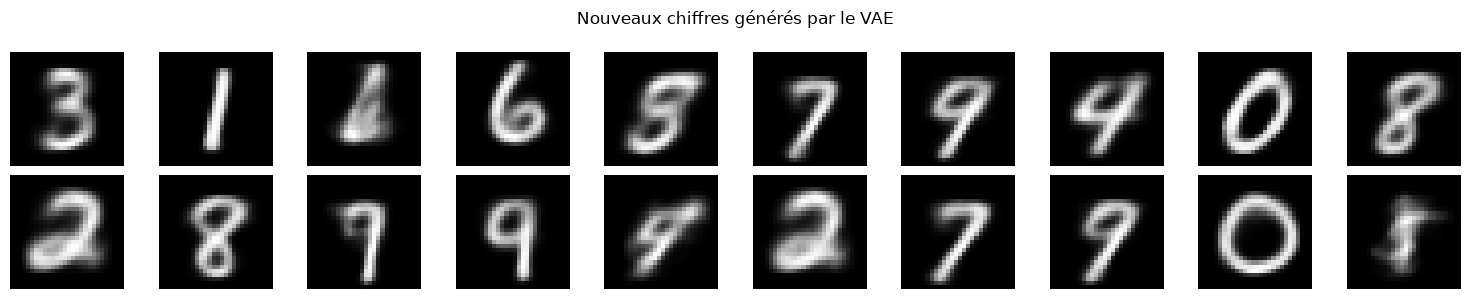

In [9]:
vae.eval()

with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
plt.show()

## 14. Explorer manuellement l'espace latent

Avec un espace latent 2D, on construit une grille de points de −3 à 3 et on observe les images produites par
le décodeur.

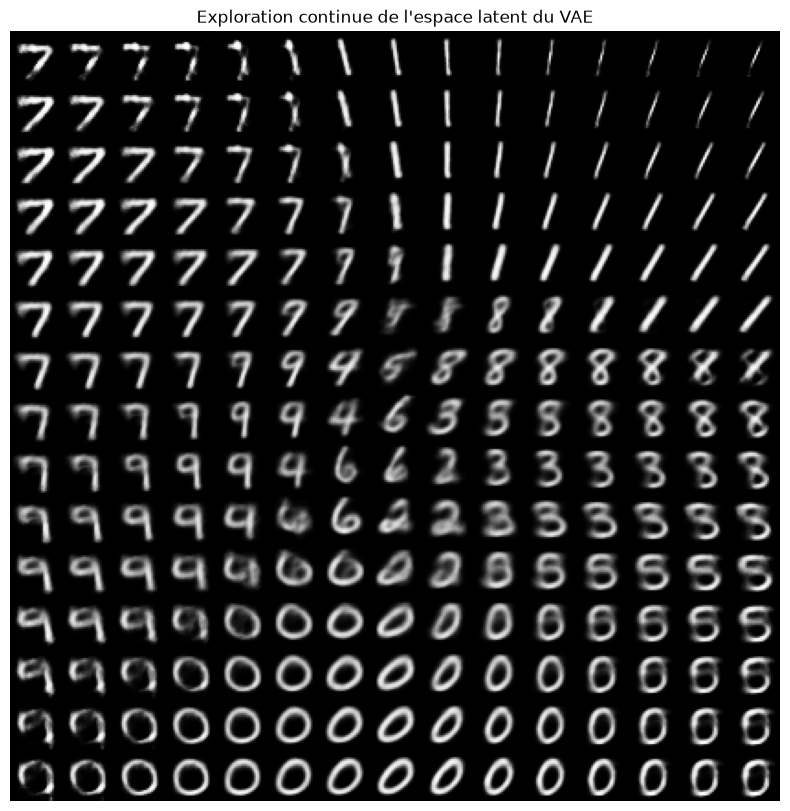

In [10]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)

figure = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)

            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]

            figure[i*28:(i+1)*28, j*28:(j+1)*28] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
plt.show()

Les chiffres se transforment progressivement les uns dans les autres : l'espace latent est **continu**.
Chaque point de la grille donne une image plausible, ce qui n'était pas le cas avec l'autoencodeur classique.